# Experiment 02 — random-action baseline visualisation

Renders the 20 init-state × 3 rollout grid for the random-action lower bound. Loads `results/can_ph.json` only — no simulation.

Headline: **0 / 60 = 0.000** success. Confirms `can/ph` is non-trivial under uniform random actions in `[-1, 1]^7`.

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

data = json.loads(Path('results/can_ph.json').read_text())
per_rollout = data['per_rollout']
print(f"env: {data['env_name']}")
print(f"n_total: {data['n_total']} "
      f"({data['n_demos_attempted']} init-states × {data['n_rollouts_per_demo']} rollouts)")
print(f"success_rate: {data['success_rate']:.3f}")
print(f"action bounds: low={data['action_low']}, high={data['action_high']}")

env: PickPlaceCan
n_total: 60 (20 init-states × 3 rollouts)
success_rate: 0.000
action bounds: low=[-1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0], high=[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


## Success grid

Rows = init-state index (`demo_<i>`), columns = rollout repetition. Green = success, red = failure. With a uniform-random policy the grid should be all red, which it is.

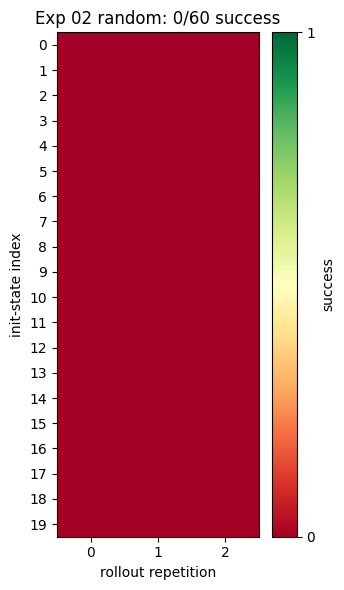

In [2]:
n_demos = data['n_demos_attempted']
n_rollouts = data['n_rollouts_per_demo']
grid = np.zeros((n_demos, n_rollouts), dtype=int)
for r in per_rollout:
    di = int(r['demo'].replace('demo_', ''))
    grid[di, r['rollout_idx']] = int(r['success'])

fig, ax = plt.subplots(figsize=(3.5, 6))
im = ax.imshow(grid, cmap='RdYlGn', vmin=0, vmax=1, aspect='auto')
ax.set_xticks(range(n_rollouts))
ax.set_yticks(range(n_demos))
ax.set_xlabel('rollout repetition')
ax.set_ylabel('init-state index')
ax.set_title(f'Exp 02 random: {int(grid.sum())}/{grid.size} success')
plt.colorbar(im, ax=ax, label='success', ticks=[0, 1])
plt.tight_layout()
plt.show()

## Per-rollout horizon distribution

All rollouts run for exactly the demo's recorded horizon (`ignore_done=True` in `experiments/common.make_env_for_dataset`); the spread comes from the underlying demo lengths.

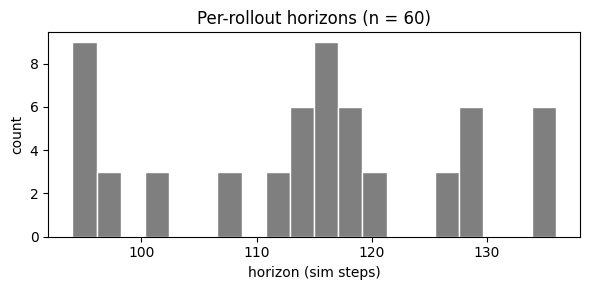

In [3]:
horizons = np.array([r['horizon'] for r in per_rollout])
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(horizons, bins=20, color='tab:gray', edgecolor='white')
ax.set_xlabel('horizon (sim steps)')
ax.set_ylabel('count')
ax.set_title(f'Per-rollout horizons (n = {len(horizons)})')
plt.tight_layout()
plt.show()

## Takeaway

0% success across 60 rollouts establishes that `can/ph` requires structured actions; any improvement above this lower bound is the value added by a learned policy or a model-based planner.